In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sbs

In [2]:
ds = pd.read_csv("RT_IOT2022", index_col=0)

ds = ds.drop(columns=['id.orig_p', 'id.resp_p'])
print(ds.select_dtypes(include=['object']).columns)

display(ds.describe())

Index(['proto', 'service', 'Attack_type'], dtype='object')


,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,bwd_pkts_per_sec,flow_pkts_per_sec,down_up_ratio,fwd_header_size_tot,...,active.avg,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size
count,123117.000000,123117.000000,123117.000000,123117.000000,123117.000000,1.231170e+05,1.231170e+05,1.231170e+05,123117.000000,123117.000000,...,1.231170e+05,1.231170e+05,1.231170e+05,1.231170e+05,1.231170e+05,1.231170e+05,1.231170e+05,123117.000000,123117.000000,123117.000000
mean,3.809566,2.268826,1.909509,1.471218,0.820260,3.518063e+05,3.517620e+05,7.035683e+05,0.854571,53.892379,...,1.481354e+05,2.353599e+04,1.616655e+06,1.701956e+06,3.517644e+06,1.664985e+06,4.550183e+04,6118.905123,2739.776018,751.647514
std,130.005408,22.336565,33.018311,19.635196,32.293948,3.707645e+05,3.708015e+05,7.415634e+05,0.337640,393.027195,...,1.613007e+06,1.477935e+06,8.809396e+06,9.252337e+06,1.229508e+08,9.007064e+06,1.091361e+06,18716.313861,10018.848534,6310.183843
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000
25%,0.000001,1.000000,1.000000,1.000000,0.000000,7.454354e+01,7.288927e+01,1.490871e+02,1.000000,20.000000,...,9.536740e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,64.000000,0.000000,64.000000
50%,0.000004,1.000000,1.000000,1.000000,0.000000,2.467238e+05,2.467238e+05,4.934475e+05,1.000000,20.000000,...,4.053116e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,64.000000,0.000000,64.000000
75%,0.000005,1.000000,1.000000,1.000000,0.000000,5.242880e+05,5.242880e+05,1.048576e+06,1.000000,20.000000,...,5.006790e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,64.000000,0.000000,64.000000
max,21728.335578,4345.000000,10112.000000,4345.000000,10105.000000,1.048576e+06,1.048576e+06,2.097152e+06,6.087899,69296.000000,...,4.374931e+08,4.774862e+08,3.000000e+08,3.000000e+08,2.096777e+10,3.000000e+08,1.208029e+08,65535.000000,65535.000000,65535.000000


In [3]:
from sklearn.preprocessing import LabelEncoder

X = ds.drop(columns=['Attack_type'])
y = ds['Attack_type']

X_encoded = pd.get_dummies(X, columns=['proto', 'service'], drop_first=True)

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Original Attack Types:", label_encoder.classes_)

Original Attack Types: ['ARP_poisioning' 'DDOS_Slowloris' 'DOS_SYN_Hping' 'MQTT_Publish'
 'Metasploit_Brute_Force_SSH' 'NMAP_FIN_SCAN' 'NMAP_OS_DETECTION'
 'NMAP_TCP_scan' 'NMAP_UDP_SCAN' 'NMAP_XMAS_TREE_SCAN' 'Thing_Speak'
 'Wipro_bulb']


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, 
    y_encoded, 
    test_size=0.2, 
    random_state=42, 
    stratify=y_encoded
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [11]:
from sklearn.ensemble import RandomForestClassifier
rfc = RandomForestClassifier(n_estimators=100, criterion='entropy', random_state=0, n_jobs=-1)
rfc.fit(X_train_scaled, y_train)
y_pred_rf = rfc.predict(X_test_scaled)

In [13]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

cm = confusion_matrix(y_test, y_pred_rf)
accuracy = accuracy_score(y_test, y_pred_rf)
print(f"Random Forest Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, target_names=label_encoder.classes_))

Random Forest Accuracy: 99.76%

Classification Report:
                            precision    recall  f1-score   support

            ARP_poisioning       0.98      0.99      0.99      1550
            DDOS_Slowloris       0.96      0.93      0.94       107
             DOS_SYN_Hping       1.00      1.00      1.00     18932
              MQTT_Publish       1.00      1.00      1.00       829
Metasploit_Brute_Force_SSH       0.78      1.00      0.88         7
             NMAP_FIN_SCAN       0.83      0.83      0.83         6
         NMAP_OS_DETECTION       1.00      1.00      1.00       400
             NMAP_TCP_scan       1.00      1.00      1.00       200
             NMAP_UDP_SCAN       0.98      0.98      0.98       518
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       402
               Thing_Speak       0.99      0.98      0.99      1622
                Wipro_bulb       0.98      0.98      0.98        51

                  accuracy                           1.00  

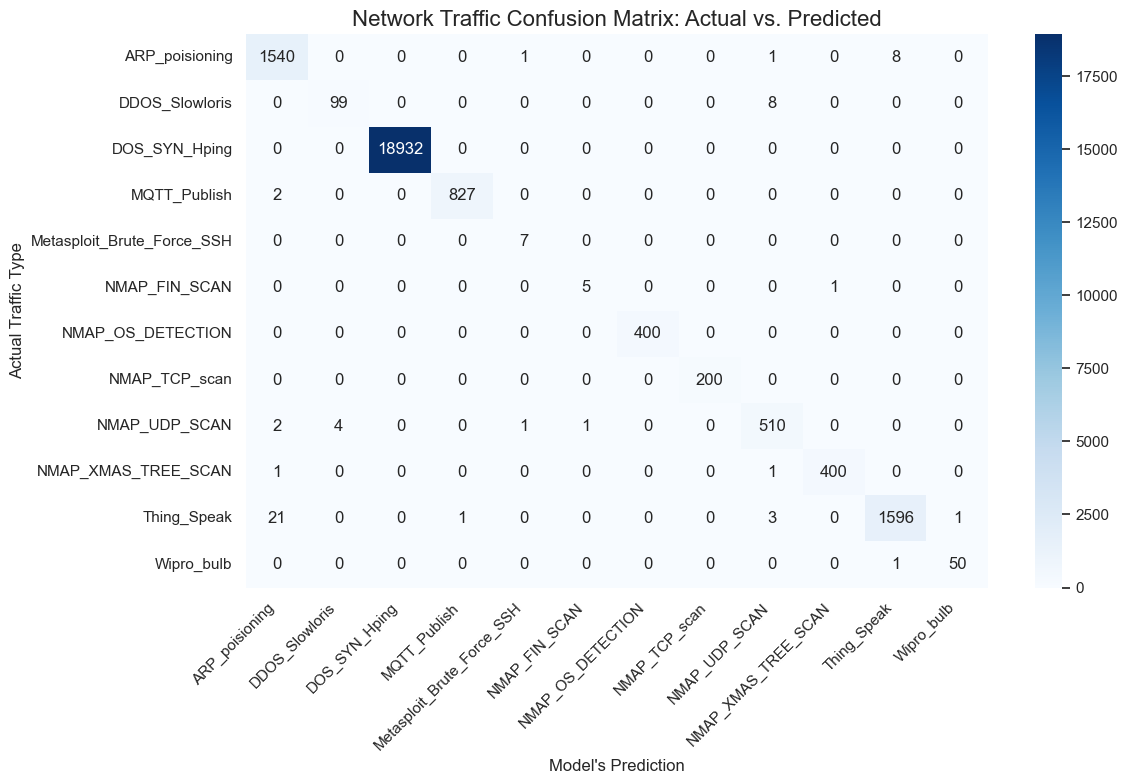

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))
sns.set_theme(style="white") # Cleaner background for heatmaps

# fmt='d' ensures the numbers print as whole integers, not scientific notation
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=label_encoder.classes_, 
            yticklabels=label_encoder.classes_)

plt.title("Network Traffic Confusion Matrix: Actual vs. Predicted", fontsize=16)
plt.ylabel("Actual Traffic Type", fontsize=12)
plt.xlabel("Model's Prediction", fontsize=12)

# Rotate the bottom labels so they don't overlap
plt.xticks(rotation=45, ha='right') 
plt.tight_layout()
plt.show()

In [5]:
from sklearn.tree import DecisionTreeClassifier
classifier = DecisionTreeClassifier(criterion='entropy' ,random_state=0)
classifier.fit(X_train_scaled, y_train)
y_pred = classifier.predict(X_test_scaled)

In [8]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

cm = confusion_matrix(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)
print(f"Random Forest Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

Random Forest Accuracy: 99.66%

Classification Report:
                            precision    recall  f1-score   support

            ARP_poisioning       0.98      0.99      0.98      1550
            DDOS_Slowloris       0.94      0.91      0.92       107
             DOS_SYN_Hping       1.00      1.00      1.00     18932
              MQTT_Publish       1.00      1.00      1.00       829
Metasploit_Brute_Force_SSH       0.62      0.71      0.67         7
             NMAP_FIN_SCAN       0.71      0.83      0.77         6
         NMAP_OS_DETECTION       1.00      1.00      1.00       400
             NMAP_TCP_scan       1.00      1.00      1.00       200
             NMAP_UDP_SCAN       0.98      0.98      0.98       518
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       402
               Thing_Speak       0.99      0.98      0.98      1622
                Wipro_bulb       0.94      0.96      0.95        51

                  accuracy                           1.00  

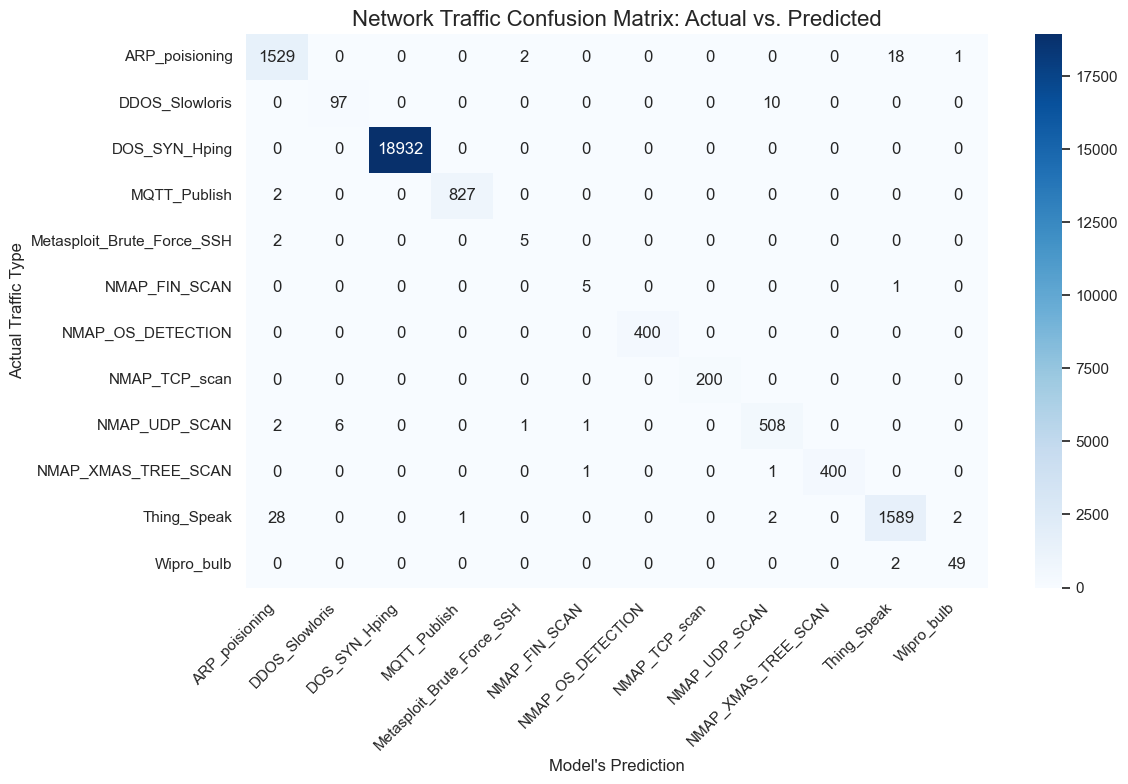

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))
sns.set_theme(style="white") # Cleaner background for heatmaps

# fmt='d' ensures the numbers print as whole integers, not scientific notation
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=label_encoder.classes_, 
            yticklabels=label_encoder.classes_)

plt.title("Network Traffic Confusion Matrix: Actual vs. Predicted", fontsize=16)
plt.ylabel("Actual Traffic Type", fontsize=12)
plt.xlabel("Model's Prediction", fontsize=12)

# Rotate the bottom labels so they don't overlap
plt.xticks(rotation=45, ha='right') 
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
gb_clf = GradientBoostingClassifier(n_estimators=20, criterion='friedman_mse',random_state=0)
gb_clf.fit(X_train_scaled, y_train)
y_pred_gb = gb_clf.predict(X_test_scaled)

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

cm = confusion_matrix(y_test, y_pred_gb)
accuracy = accuracy_score(y_test, y_pred_gb)
print(f"Random Forest Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb, target_names=label_encoder.classes_))

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))
sns.set_theme(style="white") # Cleaner background for heatmaps

# fmt='d' ensures the numbers print as whole integers, not scientific notation
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=label_encoder.classes_, 
            yticklabels=label_encoder.classes_)

plt.title("Network Traffic Confusion Matrix: Actual vs. Predicted", fontsize=16)
plt.ylabel("Actual Traffic Type", fontsize=12)
plt.xlabel("Model's Prediction", fontsize=12)

# Rotate the bottom labels so they don't overlap
plt.xticks(rotation=45, ha='right') 
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.linear_model import SGDClassifier
sgd_clf = SGDClassifier(penalty='elasticnet', )